In [1]:
import torch
from torch import nn

In [2]:
import requests #تُستخدم هذه المكتبة لتحميل ملفات البيانات أو مجموعات البيانات مباشرةً من روابط عبر الإنترنت إلى بيئة العمل
import zipfile #مكتبة مدمجة في لغة بايثون مخصصة لضغط وفك ضغط الملفات التي تستخدم صيغة الـ ZIP.
from pathlib import Path #تُستخدم لتعريف وإنشاء مسارات مجلدات البيانات

In [3]:
data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi"

if image_path.is_dir():
    print(f"{image_path} already exists ...skip download")
    
else:
    print(f"{image_path} does not exist ...creating one ")
    image_path.mkdir(parents = True, exist_ok = True)
    
    #download
    with open(data_path / "pizza_steak_sushi.zip", "wb") as f:
        request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
        print("downloading pizza steak sushi data")
        f.write(request.content)
    
    #unzip
    with zipfile.ZipFile(data_path / "pizza_steak_sushi.zip", "r") as zip_ref:
        print("unzipping pizza_steak_sushi data")
        zip_ref.extractall(image_path)

data/pizza_steak_sushi already exists ...skip download


In [4]:
from pathlib import Path
print(Path("data").resolve())

/Users/mac/Desktop/data


In [5]:
# data preparation and exploration

import os

def walk_through_dir(dir_path):
    
    #Walks through dir_path returning its contents.
    
    for dirpath, dirnames, filenames in os.walk(dir_path):
        print(f"There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}'.")

# استدعاء الدالة لتفقد محتويات مجلد الصور
walk_through_dir(image_path)

There are 2 directories and 0 images in 'data/pizza_steak_sushi'.
There are 3 directories and 0 images in 'data/pizza_steak_sushi/test'.
There are 0 directories and 19 images in 'data/pizza_steak_sushi/test/steak'.
There are 0 directories and 31 images in 'data/pizza_steak_sushi/test/sushi'.
There are 0 directories and 25 images in 'data/pizza_steak_sushi/test/pizza'.
There are 3 directories and 0 images in 'data/pizza_steak_sushi/train'.
There are 0 directories and 75 images in 'data/pizza_steak_sushi/train/steak'.
There are 0 directories and 72 images in 'data/pizza_steak_sushi/train/sushi'.
There are 0 directories and 78 images in 'data/pizza_steak_sushi/train/pizza'.


In [6]:
train_dir = image_path / "train"
test_dir = image_path / "test"

train_dir, test_dir

(PosixPath('data/pizza_steak_sushi/train'),
 PosixPath('data/pizza_steak_sushi/test'))

In [7]:
data_path

PosixPath('data')

In [8]:
image_path

PosixPath('data/pizza_steak_sushi')

[PosixPath('data/pizza_steak_sushi/test/steak/296375.jpg'), PosixPath('data/pizza_steak_sushi/test/steak/673127.jpg'), PosixPath('data/pizza_steak_sushi/test/steak/894825.jpg'), PosixPath('data/pizza_steak_sushi/test/steak/1868005.jpg'), PosixPath('data/pizza_steak_sushi/test/steak/27415.jpg'), PosixPath('data/pizza_steak_sushi/test/steak/1016217.jpg'), PosixPath('data/pizza_steak_sushi/test/steak/1285886.jpg'), PosixPath('data/pizza_steak_sushi/test/steak/502076.jpg'), PosixPath('data/pizza_steak_sushi/test/steak/3424937.jpg'), PosixPath('data/pizza_steak_sushi/test/steak/690177.jpg'), PosixPath('data/pizza_steak_sushi/test/steak/354513.jpg'), PosixPath('data/pizza_steak_sushi/test/steak/2117351.jpg'), PosixPath('data/pizza_steak_sushi/test/steak/100274.jpg'), PosixPath('data/pizza_steak_sushi/test/steak/2144308.jpg'), PosixPath('data/pizza_steak_sushi/test/steak/966174.jpg'), PosixPath('data/pizza_steak_sushi/test/steak/1882831.jpg'), PosixPath('data/pizza_steak_sushi/test/steak/3873

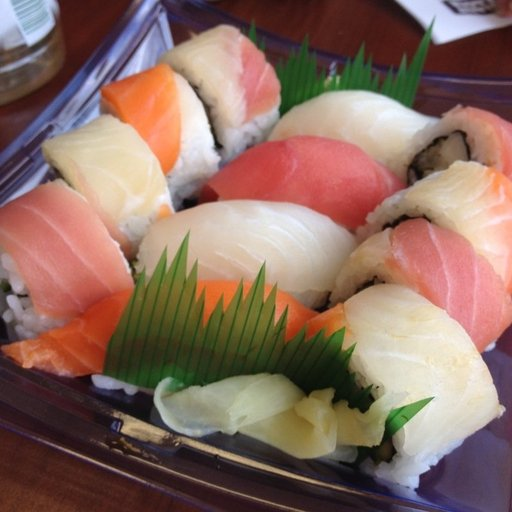

In [9]:
import random
from PIL import Image #المكتبة الأساسية في بايثون لفتح الصور، قراءتها، وتعديلها ومعالجتها.

#random.seed(42)
#get all the images
image_path_list = list(image_path.glob("*/*/*.jpg")) # تبحث داخل المجلد الأساسي عن جميع الملفات التي تطابق النمط المكتوب.glob
print(image_path_list)

#pick a random image
random_image_path = random.choice(image_path_list)
print(random_image_path)

#get image class from path name
image_class = random_image_path.parent.stem 
#.parent: تعني الانتقال مجلداً واحداً إلى أعلى
#.stem: تأخذ اسم ذلك المجلد فقط بدون امتدادات أو مسارات إضافية
print(image_class)

#open the image
img = Image.open(random_image_path)
print(f" H = {img.height} and W = {img.width}")
img

In [10]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision import transforms

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [11]:
#turn images into a pytorch tensors
#convert pil image into tensor 

data_transform = transforms.Compose([
    transforms.Resize(size = (64, 64)),
    transforms.RandomHorizontalFlip(p = 0.5),
    #pil >> tensor
    transforms.ToTensor() 
])

In [12]:
data_transform(img).shape

torch.Size([3, 64, 64])

In [13]:
data_transform(img).dtype

torch.float32

In [14]:
type(img)

PIL.JpegImagePlugin.JpegImageFile

In [15]:
data_transform(img)

tensor([[[0.3608, 0.3412, 0.3255,  ..., 0.5961, 0.6863, 0.8078],
         [0.4118, 0.3725, 0.3216,  ..., 0.6235, 0.7529, 0.8000],
         [0.4706, 0.4980, 0.5647,  ..., 0.6784, 0.7686, 0.7843],
         ...,
         [0.3412, 0.3451, 0.3333,  ..., 0.3490, 0.3490, 0.3412],
         [0.3412, 0.3490, 0.3412,  ..., 0.3529, 0.3647, 0.3569],
         [0.3333, 0.3569, 0.3529,  ..., 0.3647, 0.3608, 0.3765]],

        [[0.1725, 0.1843, 0.2392,  ..., 0.7020, 0.7725, 0.8627],
         [0.2196, 0.2353, 0.2471,  ..., 0.7255, 0.8275, 0.8510],
         [0.3569, 0.4157, 0.5137,  ..., 0.7725, 0.8314, 0.8392],
         ...,
         [0.2549, 0.2784, 0.2784,  ..., 0.1765, 0.1804, 0.1725],
         [0.2510, 0.2863, 0.2824,  ..., 0.1765, 0.1843, 0.1765],
         [0.2431, 0.2941, 0.2980,  ..., 0.1843, 0.1843, 0.1882]],

        [[0.1569, 0.1765, 0.2392,  ..., 0.8078, 0.8863, 0.9922],
         [0.2078, 0.2196, 0.2471,  ..., 0.8431, 0.9529, 0.9922],
         [0.3725, 0.4314, 0.5647,  ..., 0.8980, 0.9647, 0.

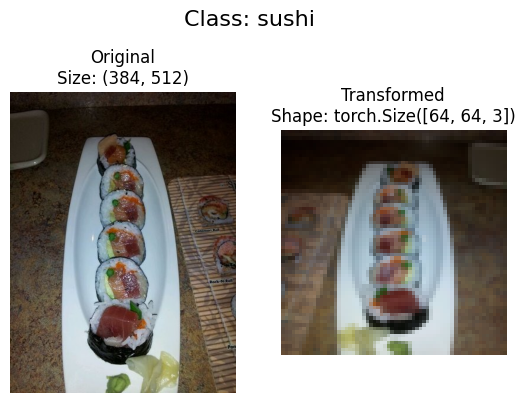

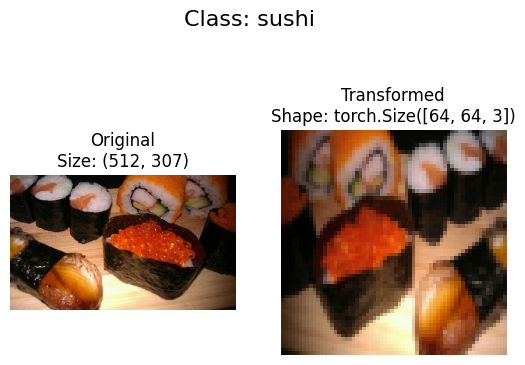

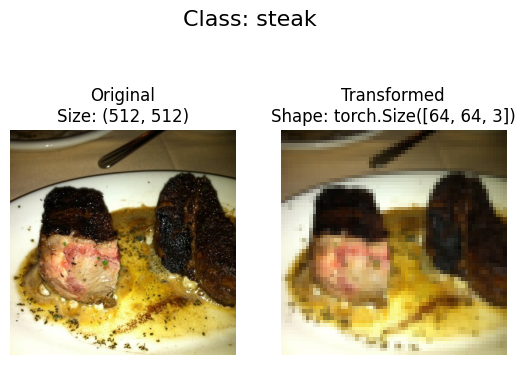

In [16]:
import matplotlib.pyplot as plt
def plot_transformed_images(image_paths: list, transform, n=3, seed=None):
    """
    Selects random images from a path of images and loads/transforms
    them then plots the original vs the transformed version.
    """
    if seed:
        random.seed(seed)
    random_image_paths = random.sample(image_paths, k=n)
    for image_path in random_image_paths:
        with Image.open(image_path) as f:
            fig, ax = plt.subplots(nrows=1, ncols=2)
            ax[0].imshow(f)
            ax[0].set_title(f"Original\nSize: {f.size}")
            ax[0].axis(False)
            
            # Transform and plot target image
            transformed_image = transform(f).permute(1, 2, 0) # note we will need to change shape for matplotlib
            ax[1].imshow(transformed_image)
            ax[1].set_title(f"Transformed\nShape: {transformed_image.shape}")
            ax[1].axis("off")
            
            fig.suptitle(f"Class: {image_path.parent.stem}", fontsize=16)

# استدعاء الدالة لتطبيقها وعرض الصور
plot_transformed_images(image_paths=image_path_list,
                        transform=data_transform,
                        n=3)

In [17]:
train_dir

PosixPath('data/pizza_steak_sushi/train')

In [18]:
#create dataset
from torchvision import datasets
train_data = datasets.ImageFolder(root = train_dir,
                                   transform = data_transform,
                                   target_transform = None)

test_data = datasets.ImageFolder(root = test_dir,
                                  transform = data_transform) 
train_data, test_data

(Dataset ImageFolder
     Number of datapoints: 225
     Root location: data/pizza_steak_sushi/train
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 75
     Root location: data/pizza_steak_sushi/test
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ))

In [19]:
#class names
class_names = train_data.classes
class_names

['pizza', 'steak', 'sushi']

In [20]:
#class names as dictionary
class_dict = train_data.class_to_idx
class_dict

{'pizza': 0, 'steak': 1, 'sushi': 2}

In [21]:
len(train_data), len(test_data)

(225, 75)

In [22]:
train_data.targets

[0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2]

In [23]:
train_data.samples[0]

('data/pizza_steak_sushi/train/pizza/1008844.jpg', 0)

In [24]:
img, label = train_data[0][0], train_data[0][1]
print(f"Image tensor:\n {img}")
print(f"Image shape: {img.shape}")
print(f"Image datatype: {img.dtype}")
print(f"Image label: {label}")
print(f"Label datatype: {type(label)}")

Image tensor:
 tensor([[[0.1176, 0.1216, 0.1255,  ..., 0.0980, 0.1020, 0.1137],
         [0.1294, 0.1294, 0.1294,  ..., 0.0980, 0.0980, 0.1059],
         [0.1333, 0.1333, 0.1333,  ..., 0.0941, 0.0980, 0.1020],
         ...,
         [0.1686, 0.1647, 0.1686,  ..., 0.1255, 0.1098, 0.1098],
         [0.1686, 0.1647, 0.1686,  ..., 0.1098, 0.0941, 0.0902],
         [0.1647, 0.1647, 0.1686,  ..., 0.0980, 0.0863, 0.0863]],

        [[0.0588, 0.0588, 0.0588,  ..., 0.0745, 0.0706, 0.0745],
         [0.0627, 0.0627, 0.0627,  ..., 0.0745, 0.0706, 0.0745],
         [0.0706, 0.0706, 0.0706,  ..., 0.0745, 0.0745, 0.0706],
         ...,
         [0.2392, 0.2392, 0.2510,  ..., 0.1373, 0.1333, 0.1255],
         [0.2314, 0.2392, 0.2510,  ..., 0.1255, 0.1176, 0.1098],
         [0.2275, 0.2353, 0.2431,  ..., 0.1137, 0.1059, 0.1020]],

        [[0.0196, 0.0196, 0.0157,  ..., 0.0902, 0.0902, 0.0941],
         [0.0196, 0.0157, 0.0196,  ..., 0.0902, 0.0863, 0.0902],
         [0.0196, 0.0157, 0.0157,  ..., 0.0

In [25]:
img.dtype

torch.float32

Original shape: torch.Size([3, 64, 64]) -> [color_channels, height, width]
Image permute: torch.Size([64, 64, 3]) -> [height, width, color_channels]


Text(0.5, 1.0, 'pizza')

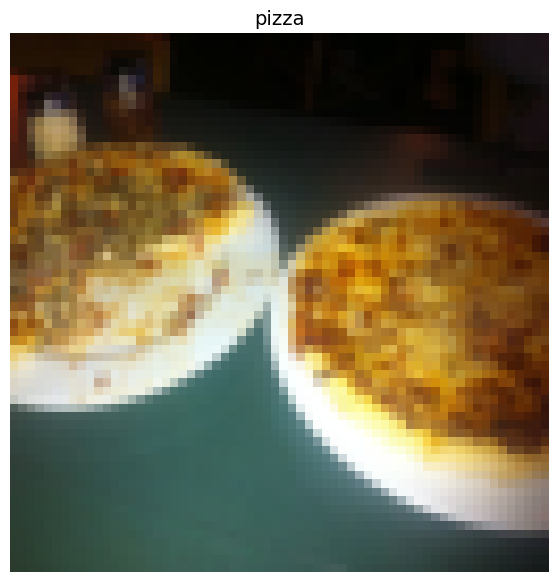

In [26]:
#عرض الصورة
# Rearrange the order dimensions
img_permute = img.permute(1, 2, 0)

# Print out different shapes
print(f"Original shape: {img.shape} -> [color_channels, height, width]")
print(f"Image permute: {img_permute.shape} -> [height, width, color_channels]")

# Plot the image
plt.figure(figsize=(10, 7))
plt.imshow(img_permute)
plt.axis("off")
plt.title(class_names[label], fontsize=14)

In [27]:
import os
os.cpu_count()

12

In [28]:
from torch.utils.data import DataLoader

BATCH_SIZE = 1

train_dataloader = DataLoader(dataset = train_data,
                              batch_size = BATCH_SIZE,
                              num_workers = 1,
                              shuffle = True)

test_dataloader = DataLoader(dataset = test_data,
                             batch_size = BATCH_SIZE,
                             num_workers = 1,
                             shuffle = False)

train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x1299bbe90>,
 <torch.utils.data.dataloader.DataLoader at 0x1299137a0>)

In [29]:
len(train_dataloader), len(test_dataloader) #because BATCH_SIZE = 1

(225, 75)

In [30]:
img, label = next(iter(train_dataloader))

# Batch size will now be 1, you can change the batch size if you like
print(f"Image shape: {img.shape} -> [batch_size, color_channels, height, width]")
print(f"Label shape: {label.shape}")

Image shape: torch.Size([1, 3, 64, 64]) -> [batch_size, color_channels, height, width]
Label shape: torch.Size([1])


### 6. Other forms of transforms (data augmentation)

* **ما هو تعزيز البيانات (Data Augmentation)؟**
  هي عملية تهدف إلى إضافة تنوع واختلافات بشكل اصطناعي لبيانات التدريب الخاصة بك

* **كيف يتم تطبيقها؟**
  في مجال الصور، تعني تطبيق سلسلة من التحويلات والتعديلات المختلفة على صور التدريب الأصلية (مثل القلب، التدوير، وتغيير الإضاءة)

* **الهدف منها:**
  منع النموذج من الحفظ الأعمى (Overfitting) وجعله أكثر قدرة على التعميم والتعرف على الصور في مختلف الظروف والزوايا.
  +increase the diversity of the dataset

### TrivialAugment (تعزيز البيانات التلقائي)

* **ما هو المفهوم الأساسي؟**
  هي خوارزمية ذكية لتعزيز البيانات تهدف إلى تحسين وتنوع صور التدريب دون الحاجة للضبط اليدوي المعقد للإعدادات.

* **كيف تعمل؟**
  تقوم الخوارزمية تلقائياً باختيار تحويل عشوائي واحد (مثل التدوير، القلب، أو تعديل السطوع) لكل صورة يتم إدخالها وبدرجة قوة عشوائية في كل مرة.

* **الفوائد الرئيسية:**
  * توفر الوقت والجهد في كتابة وتجربة قواعد تحويل متعددة يدوياً.
  * تمنع النموذج من الحفظ الأعمى (Overfitting) وتزيد من دقته وقدرته على التعميم.
  * مدمجة مباشرة وسهلة الاستخدام ضمن مكتبة PyTorch.

In [31]:
from torchvision import transforms

train_transform = transforms.Compose([transforms.Resize(size = (224, 224)),
                                      transforms.TrivialAugmentWide(num_magnitude_bins = 31),
                                      transforms.ToTensor()])

test_transform = transforms.Compose([transforms.Resize(size = (224, 224)),
                                      transforms.ToTensor()])

In [32]:
# Get all image paths
image_path_list = list(image_path.glob("*/*/*.jpg"))
image_path_list[:10]

[PosixPath('data/pizza_steak_sushi/test/steak/296375.jpg'),
 PosixPath('data/pizza_steak_sushi/test/steak/673127.jpg'),
 PosixPath('data/pizza_steak_sushi/test/steak/894825.jpg'),
 PosixPath('data/pizza_steak_sushi/test/steak/1868005.jpg'),
 PosixPath('data/pizza_steak_sushi/test/steak/27415.jpg'),
 PosixPath('data/pizza_steak_sushi/test/steak/1016217.jpg'),
 PosixPath('data/pizza_steak_sushi/test/steak/1285886.jpg'),
 PosixPath('data/pizza_steak_sushi/test/steak/502076.jpg'),
 PosixPath('data/pizza_steak_sushi/test/steak/3424937.jpg'),
 PosixPath('data/pizza_steak_sushi/test/steak/690177.jpg')]

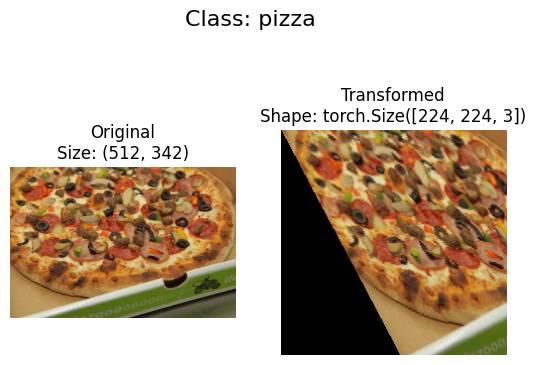

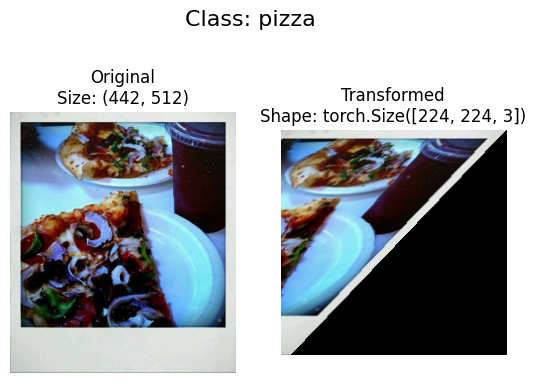

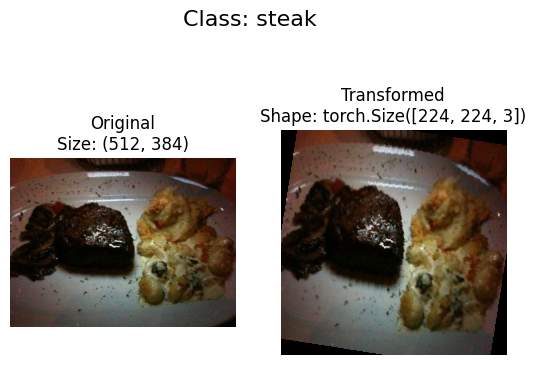

In [33]:
# Plot random transformed images
plot_transformed_images(
    image_paths=image_path_list,
    transform=train_transform,
    n = 3,
    seed = None
)

### model_0

In [34]:
from torchvision import transforms
simple_transforms = transforms.Compose([transforms.Resize(size=(64, 64)),
                                           transforms.ToTensor()])

In [35]:
from torchvision import datasets
train_data_simple = datasets.ImageFolder(root = train_dir,
                                         transform = simple_transforms)
test_data_simple = datasets.ImageFolder(root = test_dir,
                                        transform = simple_transforms)

In [36]:
train_data_simple, test_data_simple

(Dataset ImageFolder
     Number of datapoints: 225
     Root location: data/pizza_steak_sushi/train
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 75
     Root location: data/pizza_steak_sushi/test
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                ToTensor()
            ))

In [37]:
from torch.utils.data import DataLoader
BATCH_SIZE = 32
NUM_WORKERS = 0
train_dataloader_simple = DataLoader(dataset = train_data_simple,
                                     batch_size = BATCH_SIZE,
                                     num_workers = NUM_WORKERS,
                                     shuffle = True)
test_dataloader_simple = DataLoader(dataset = test_data_simple,
                                    batch_size = BATCH_SIZE,
                                     num_workers = NUM_WORKERS,
                                     shuffle = False)

In [38]:
train_dataloader_simple, test_dataloader_simple

(<torch.utils.data.dataloader.DataLoader at 0x129c4c620>,
 <torch.utils.data.dataloader.DataLoader at 0x129c4ddf0>)

In [39]:
class TinyVGG(nn.Module):
    def __init__(self,
                 input_shape : int,
                 hidden_units : int,
                 output_shape : int):
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels = input_shape,
                      out_channels = hidden_units,
                      kernel_size = 3,
                      padding = 1,
                      stride = 1),
            
            nn.ReLU(),
            nn.Conv2d(in_channels = hidden_units,
                      out_channels = hidden_units,
                      kernel_size = 3,
                      padding = 0,
                      stride = 1),
            
            nn.ReLU(),
            nn.MaxPool2d(kernel_size = 2,
                     stride = 2) # must be the same size as kernel_size = 2
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(in_channels = hidden_units,
                      out_channels = hidden_units,
                      kernel_size = 3,
                      padding = 0,
                      stride = 1),
            nn.ReLU(),
            nn.Conv2d(in_channels = hidden_units,
                      out_channels = hidden_units,
                      kernel_size = 3,
                      padding = 0,
                      stride = 1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size = 2,
                     stride = 2)
        ) 
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(
                in_features = hidden_units*13*13,
                out_features = output_shape
            )
            
        )
    def forward(self, x):
        
        
        
        x = self.conv_block_1(x)
        #print(x.shape)
        x = self.conv_block_2(x)
        #print(x.shape)
        x = self.classifier(x)
        #print(x.shape)
        return x
        #return self.classifier(self.conv_block_2(self.conv_block_1(x)))

In [40]:
torch.manual_seed(42)
model_0 = TinyVGG(input_shape = 3,
                  hidden_units = 10,
                  output_shape = len(class_names))
model_0

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1690, out_features=3, bias=True)
  )
)

In [41]:
#get a single image batch
image_batch, label_batch = next(iter(train_dataloader_simple))
image_batch.shape, label_batch.shape

(torch.Size([32, 3, 64, 64]), torch.Size([32]))

In [42]:
10*13*13

1690

In [43]:
#try forward pass 
model_0(image_batch)

tensor([[ 0.0202, -0.0022,  0.0100],
        [ 0.0186,  0.0031,  0.0064],
        [ 0.0185,  0.0011,  0.0090],
        [ 0.0248, -0.0038,  0.0093],
        [ 0.0191,  0.0009,  0.0103],
        [ 0.0208,  0.0020,  0.0050],
        [ 0.0219,  0.0006,  0.0124],
        [ 0.0214, -0.0023,  0.0095],
        [ 0.0249, -0.0045,  0.0082],
        [ 0.0194, -0.0005,  0.0110],
        [ 0.0226, -0.0009,  0.0091],
        [ 0.0220, -0.0020,  0.0097],
        [ 0.0213, -0.0043,  0.0082],
        [ 0.0229, -0.0009,  0.0100],
        [ 0.0212, -0.0046,  0.0090],
        [ 0.0217, -0.0041,  0.0101],
        [ 0.0217, -0.0052,  0.0109],
        [ 0.0214, -0.0016,  0.0084],
        [ 0.0200, -0.0001,  0.0087],
        [ 0.0189,  0.0014,  0.0081],
        [ 0.0201,  0.0015,  0.0086],
        [ 0.0198, -0.0036,  0.0102],
        [ 0.0221, -0.0002,  0.0084],
        [ 0.0241, -0.0026,  0.0095],
        [ 0.0218, -0.0022,  0.0087],
        [ 0.0178,  0.0026,  0.0075],
        [ 0.0213, -0.0018,  0.0084],
 

In [44]:
import torchinfo
from torchinfo import summary

summary(model_0, input_size = [1, 3, 64, 64])

Layer (type:depth-idx)                   Output Shape              Param #
TinyVGG                                  [1, 3]                    --
├─Sequential: 1-1                        [1, 10, 31, 31]           --
│    └─Conv2d: 2-1                       [1, 10, 64, 64]           280
│    └─ReLU: 2-2                         [1, 10, 64, 64]           --
│    └─Conv2d: 2-3                       [1, 10, 62, 62]           910
│    └─ReLU: 2-4                         [1, 10, 62, 62]           --
│    └─MaxPool2d: 2-5                    [1, 10, 31, 31]           --
├─Sequential: 1-2                        [1, 10, 13, 13]           --
│    └─Conv2d: 2-6                       [1, 10, 29, 29]           910
│    └─ReLU: 2-7                         [1, 10, 29, 29]           --
│    └─Conv2d: 2-8                       [1, 10, 27, 27]           910
│    └─ReLU: 2-9                         [1, 10, 27, 27]           --
│    └─MaxPool2d: 2-10                   [1, 10, 13, 13]           --
├─Sequentia

In [45]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params = model_0.parameters(),
                            lr = 0.001  #default for adam optimizer
                            )

In [46]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

# نقل النموذج للـ GPU الخاص بالماك (MPS)
model_0 = model_0.to(device)

Using device: mps


In [47]:
#create train loop
def train_step(model:torch.nn.Module,
               dataloader:torch.utils.data.DataLoader,
               loss_fn:torch.nn.Module,
               optimizer:torch.optim.Optimizer):
    model.train()
    train_loss, train_acc = 0, 0
    
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)
        y_pred = model(X)
        loss= loss_fn(y_pred, y)
        train_loss += loss.item()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
        train_acc += (y_pred_class == y).sum().item() / len(y_pred)
        
    train_loss = train_loss / len(dataloader)
    train_acc = train_acc / len(dataloader)
    print(f"train loss : {train_loss:.5f} | train acc : {train_acc * 100:.2f}%")

In [48]:
#create test loop
def test_step(model:torch.nn.Module,
              dataloader:torch.utils.data.DataLoader,
              loss_fn:torch.nn.Module):
    model.eval()
    test_loss, test_acc = 0, 0
    
    with torch.inference_mode():
        for batch, (X, y) in enumerate(dataloader):
            X, y = X.to(device), y.to(device)
            test_pred_logits = model(X)
            loss = loss_fn(test_pred_logits, y)
            test_loss += loss.item()  
            test_pred_labels = test_pred_logits.argmax(dim=1)
            test_acc += (test_pred_labels == y).sum().item() / len(test_pred_labels)
            
    test_loss = test_loss / len(dataloader)
    test_acc = test_acc /len(dataloader)
    print(f"test loss : {test_loss:.5f} | test acc : {test_acc * 100:.2f}%")

In [49]:
from timeit import default_timer as timer
from tqdm.auto import tqdm
torch.manual_seed(42)

epochs = 5

train_time_start = timer()
for epoch in tqdm(range(epochs)):
    print(f"epoch : {epoch}")
    train_step(model = model_0,
               dataloader = train_dataloader_simple,
               loss_fn = loss_fn,
               optimizer = optimizer)
    test_step(model = model_0,
              dataloader = test_dataloader_simple,
              loss_fn = loss_fn)
train_time_end = timer()

print(f"total train time : {train_time_end - train_time_start:.4f} seconds")

  0%|          | 0/5 [00:00<?, ?it/s]

epoch : 0
train loss : 1.10323 | train acc : 25.00%


 20%|██        | 1/5 [00:04<00:16,  4.15s/it]

test loss : 1.09945 | test acc : 26.04%
epoch : 1
train loss : 1.07481 | train acc : 42.58%


 40%|████      | 2/5 [00:06<00:09,  3.15s/it]

...

test loss : 1.15979 | test acc : 26.04%
epoch : 3
train loss : 1.10507 | train acc : 30.47%


 80%|████████  | 4/5 [00:11<00:02,  2.74s/it]

test loss : 1.14716 | test acc : 27.08%
epoch : 4
train loss : 1.07636 | train acc : 37.89%


100%|██████████| 5/5 [00:14<00:00,  2.82s/it]

test loss : 1.14133 | test acc : 26.04%
total train time : 14.1072 seconds
